In [3]:
import os
import getpass
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

sns.set_style("whitegrid")
os.makedirs("images", exist_ok=True)

password = getpass.getpass("PostgreSQL password: ")
url = URL.create("postgresql+psycopg", username="postgres", password=password,
                 host="localhost", port=5432, database="chinook")
engine = create_engine(url)

pd.read_sql("SELECT COUNT(*) AS invoices FROM invoice", engine)

,invoices
0,412


In [4]:
countries = pd.read_sql("""
    SELECT billing_country AS country, ROUND(SUM(total), 2) AS revenue
    FROM invoice GROUP BY billing_country ORDER BY revenue DESC LIMIT 8
""", engine)

regions = pd.read_sql("""
    SELECT CASE
             WHEN billing_country IN ('USA', 'Canada') THEN 'North America'
             WHEN billing_country IN ('Brazil', 'Chile', 'Argentina') THEN 'South America'
             WHEN billing_country = 'India' THEN 'Asia'
             WHEN billing_country = 'Australia' THEN 'Oceania'
             ELSE 'Europe'
           END AS region,
           ROUND(SUM(total), 2) AS revenue
    FROM invoice GROUP BY region ORDER BY revenue DESC
""", engine)

genres = pd.read_sql("""
    SELECT g.name AS genre, ROUND(SUM(il.unit_price * il.quantity), 2) AS revenue
    FROM invoice_line il
    JOIN track t ON t.track_id = il.track_id
    JOIN genre g ON g.genre_id = t.genre_id
    GROUP BY g.name ORDER BY revenue DESC LIMIT 8
""", engine)

monthly = pd.read_sql("""
    SELECT TO_CHAR(invoice_date, 'YYYY-MM') AS month, ROUND(SUM(total), 2) AS revenue
    FROM invoice GROUP BY month ORDER BY month
""", engine)

for df_ in (countries, regions, genres, monthly):
    df_["revenue"] = df_["revenue"].astype(float)

print(len(countries), len(regions), len(genres), len(monthly))

8 5 8 60


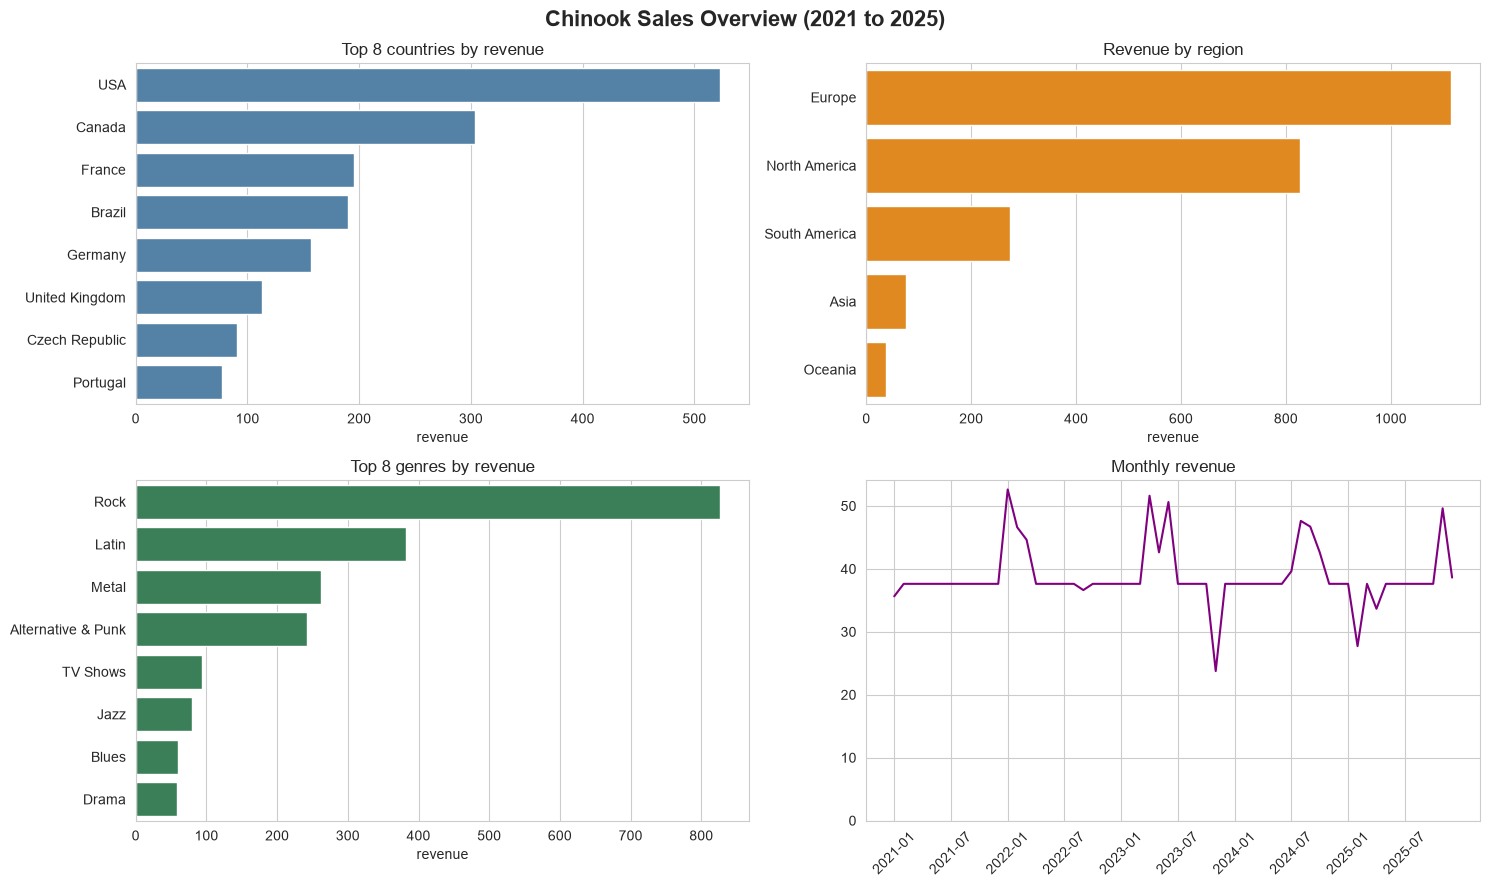

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
fig.suptitle("Chinook Sales Overview (2021 to 2025)", fontsize=16, fontweight="bold")

sns.barplot(data=countries, y="country", x="revenue", ax=axes[0, 0], color="steelblue")
axes[0, 0].set_title("Top 8 countries by revenue")

sns.barplot(data=regions, y="region", x="revenue", ax=axes[0, 1], color="darkorange")
axes[0, 1].set_title("Revenue by region")

sns.barplot(data=genres, y="genre", x="revenue", ax=axes[1, 0], color="seagreen")
axes[1, 0].set_title("Top 8 genres by revenue")

axes[1, 1].plot(monthly["month"], monthly["revenue"], color="purple")
axes[1, 1].set_ylim(bottom=0)
axes[1, 1].set_title("Monthly revenue")
axes[1, 1].set_xticks(range(0, len(monthly), 6))
axes[1, 1].set_xticklabels(monthly["month"][::6], rotation=45)

for ax in axes.flat:
    ax.set_ylabel("")

plt.tight_layout()
plt.savefig("images/sales_overview.png", dpi=150, bbox_inches="tight")
plt.show()